In [ ]:
!pip install datasets
from huggingface_hub import login
login()
from datasets import load_dataset
dataset = load_dataset("stanfordnlp/imdb")

In [ ]:
print(type(dataset))

<class 'datasets.dataset_dict.DatasetDict'>


In [ ]:
!pip install nltk
import nltk
nltk.download('punkt_tab')
import torch

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('stopwords')
trans = str.maketrans('', '', string.punctuation)
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
from nltk.tokenize import sent_tokenize
def yield_tokens(dataset):
  for example in dataset:
    text = example['text'].replace('<br />',' ')
    text = text.replace('<br>',' ')

    sentences = sent_tokenize(text)
    sentences = [sentence.strip() for sentence in sentences]
    sentences = [sentence.lower() for sentence in sentences]
    sentences = [sentence for sentence in sentences if len(sentence) > 0]
    sentences= [sentence.translate(trans) for sentence in sentences]
    yield sentences
sentence_tokens_train = yield_tokens(dataset['train'])
sentence_tokens_test = yield_tokens(dataset['test'])
sentence_tokens = [sentence_tokens_train, sentence_tokens_test]

In [ ]:
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

def get_wordnet_pos(tag):
    if tag.startswith('V'):
        return 'v'
    elif tag.startswith('J'):      # JJ, JJR, JJS — adjectives
        return 'a'
    elif tag.startswith('R'):      # RB, RBR, RBS — adverbs
        return 'r'
    else:
        return 'n'                 # default: noun
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
def yield_word_tokens(sentence_tokens):
  for sentences in sentence_tokens:
    review_words = []
    for sentence in sentences:

      word = word_tokenize(sentence)
      word = pos_tag(word)
      word = [(w[0], get_wordnet_pos(w[1])) for w in word]
      word = [lemmatizer.lemmatize(w[0], w[1]) for w in word]
      word = [w for w in word if w not in stop_words]
      word = [w for w in word if len(w) > 0]
      review_words.append(word)
    yield review_words
word_tokens_train = yield_word_tokens(sentence_tokens_train)
word_tokens_test = yield_word_tokens(sentence_tokens_test)
word_tokens = [word_tokens_train, word_tokens_test]







In [ ]:
from collections import Counter
from tqdm import tqdm

# 1. Run the heavy NLTK processing ONCE and store it in RAM
print("Processing NLP tags (this will take a minute or two, but only happens once!)...")
train_word_lists = list(tqdm(yield_word_tokens(sentence_tokens_train), total=25000))

# 1. Build the vocabulary
counter = Counter()
for review in train_word_lists:
    for sentence in review:
        # sentence is a list of strings, which Counter can handle perfectly!
        counter.update(sentence)

vocab_dict = {word: i+2 for i, (word, freq) in enumerate(counter.most_common(20000))}
vocab_dict['<pad>'] = 0
vocab_dict['<unk>'] = 1

# 3. Convert to IDs instantly using the pre-calculated list
all_ids_train = [
    [vocab_dict.get(word, vocab_dict['<unk>']) for sentence in review for word in sentence]
    for review in train_word_lists
]

test_word_lists = list(tqdm(yield_word_tokens(sentence_tokens_test), total=25000))
all_ids_test = [
    [vocab_dict.get(word, vocab_dict['<unk>']) for sentence in review for word in sentence]
    for review in test_word_lists
]


Processing NLP tags (this will take a minute or two, but only happens once!)...


100%|██████████| 25000/25000 [04:20<00:00, 96.15it/s] 


In [ ]:
print(type(word_tokens))

<class 'list'>


In [ ]:

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
class IMDBDataset(Dataset):
    def __init__(self, all_ids, labels):
        self.texts = all_ids
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return torch.tensor(self.texts[idx]), torch.tensor(self.labels[idx])

train_dataset = IMDBDataset(all_ids_train, dataset['train']['label'])
test_dataset = IMDBDataset(all_ids_test, dataset['test']['label'])

def collate_fn(batch):
    # 'batch' is a list of tuples: [(text_tensor_1, label_1), (text_tensor_2, label_2), ...]
    texts = [item[0] for item in batch]
    labels = [item[1] for item in batch]

    # Calculate the original lengths BEFORE padding
    lengths = torch.tensor([len(t) for t in texts])

    # Pad the texts so they are all the length of the longest review in THIS batch
    texts_padded = pad_sequence(texts, batch_first=True, padding_value=0)
    labels = torch.stack(labels)

    # Return all THREE items
    return texts_padded, labels, lengths

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

In [ ]:
def evaluate(loader):
    model.eval()  # dropout/batchnorm off (RNN mein zyada farak nahi padta, but good practice)
    correct = 0
    total = 0
    with torch.no_grad():  # gradients track mat karo, memory/speed bachao
        for x, y, lengths in loader:
            x, y = x.to(device), y.to(device).float()
            logits = model(x, lengths)
            preds = (torch.sigmoid(logits) > 0.5).float()  # probability > 0.5 → positive
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
import torch.nn as nn

class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)   # unchanged
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)   # still single hidden state, no (h,c)
        out = self.fc(self.dropout(hidden[-1]))
        return out.squeeze(1)

model = RNNClassifier(vocab_size=len(vocab_dict)).to(device)

In [ ]:
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-5)

train_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(20):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for x, y, lengths in train_loader:
        x, y = x.to(device), y.to(device).float()
        optimizer.zero_grad()
        output = model(x, lengths)
        loss = criterion(output, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
        preds = (torch.sigmoid(output) > 0.5).float()
        correct += (preds == y).sum().item()
        total += y.size(0)

    epoch_loss = total_loss / len(train_loader)
    epoch_acc = correct / total
    test_acc = evaluate(test_loader)   # uses your existing evaluate() function

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    test_accuracies.append(test_acc)

    print(f"Epoch {epoch+1}, Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc:.4f}, Test Acc: {test_acc:.4f}")

Epoch 1, Loss: 0.6205, Train Acc: 0.6530, Test Acc: 0.7298
Epoch 2, Loss: 0.5106, Train Acc: 0.7643, Test Acc: 0.7801
Epoch 3, Loss: 0.4390, Train Acc: 0.8098, Test Acc: 0.8077
Epoch 4, Loss: 0.3851, Train Acc: 0.8411, Test Acc: 0.8187
Epoch 5, Loss: 0.3392, Train Acc: 0.8649, Test Acc: 0.8282
Epoch 6, Loss: 0.3047, Train Acc: 0.8810, Test Acc: 0.8336
Epoch 7, Loss: 0.2733, Train Acc: 0.8952, Test Acc: 0.8329
Epoch 8, Loss: 0.2438, Train Acc: 0.9092, Test Acc: 0.8155
Epoch 9, Loss: 0.2142, Train Acc: 0.9212, Test Acc: 0.8312
Epoch 10, Loss: 0.1872, Train Acc: 0.9333, Test Acc: 0.8334
Epoch 11, Loss: 0.1646, Train Acc: 0.9416, Test Acc: 0.8375


KeyboardInterrupt: 

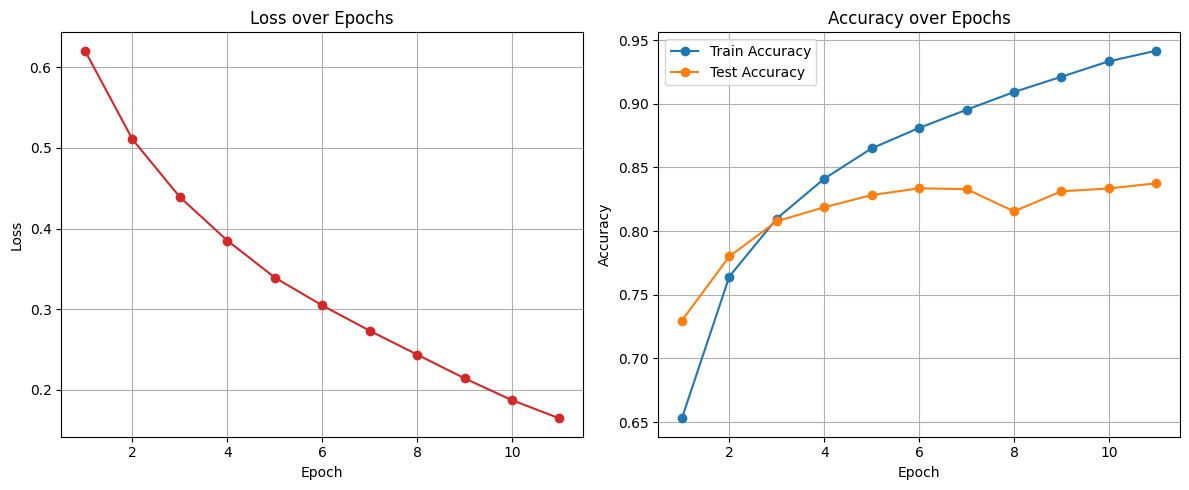

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Loss vs Epoch
axes[0].plot(epochs, train_losses, marker='o', color='tab:red')
axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

# Accuracy vs Epoch
axes[1].plot(epochs, train_accuracies, marker='o', label='Train Accuracy')
axes[1].plot(epochs, test_accuracies, marker='o', label='Test Accuracy')
axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import random
import torch

def text_to_ids(text):
    """Applies the exact same NLP preprocessing steps used on the training data."""
    # 1. Clean and sentence tokenize
    text = text.replace('<br />',' ').replace('<br>',' ')
    sentences = sent_tokenize(text)
    sentences = [s.strip().lower() for s in sentences]
    sentences = [s for s in sentences if len(s) > 0]
    sentences = [s.translate(trans) for s in sentences]

    # 2. Word tokenize, pos tag, lemmatize, remove stopwords, and convert to IDs
    flat_ids = []
    for sentence in sentences:
        words = word_tokenize(sentence)
        words = pos_tag(words)
        words = [(w[0], get_wordnet_pos(w[1])) for w in words]
        words = [lemmatizer.lemmatize(w[0], w[1]) for w in words]
        words = [w for w in words if w not in stop_words and len(w) > 0]

        for w in words:
            flat_ids.append(vocab_dict.get(w, vocab_dict['<unk>']))

    # PyTorch's pack_padded_sequence will crash if a sequence has a length of 0.
    # If a review is completely emptied by stop-word removal, give it a single <unk> token.
    if len(flat_ids) == 0:
        flat_ids = [vocab_dict['<unk>']]

    return flat_ids

def show_predictions(dataset_split, n=8):
    model.eval()
    label_map = {0: 'Negative', 1: 'Positive'}

    indices = random.sample(range(len(dataset_split)), n)

    with torch.no_grad():
        for idx in indices:
            # HuggingFace datasets allow row-based indexing
            text = dataset_split[idx]['text']
            true_label = dataset_split[idx]['label']

            ids = text_to_ids(text)
            x = torch.tensor(ids).unsqueeze(0).to(device)   # batch of 1
            lengths = torch.tensor([len(ids)])

            logit = model(x, lengths)
            prob = torch.sigmoid(logit).item()
            pred_label = 1 if prob > 0.5 else 0

            correct = "✅" if pred_label == true_label else "❌"

            print(f"{correct} True: {label_map[true_label]:9s} | Predicted: {label_map[pred_label]:9s} (conf: {prob:.2f})")
            print(f"   Text: {text[:200]}{'...' if len(text) > 200 else ''}")
            print("-" * 100)

# Run it on the test set!
show_predictions(dataset['test'], n=8)

✅ True: Negative  | Predicted: Negative  (conf: 0.05)
   Text: The mission to see the movie "The Cave" was a dream of a friend of mine after witnessing the highly dramatic trailer, full of flashes of a creature lurking in a cave, some young cave divers, and not m...
----------------------------------------------------------------------------------------------------
✅ True: Positive  | Predicted: Positive  (conf: 0.61)
   Text: When I first saw the ad for this, I was like 'Oh here we go. He's done High School Musical, but he can't coast along on that so now he's making appearances on other Disney shows'. Personally, I love T...
----------------------------------------------------------------------------------------------------
✅ True: Negative  | Predicted: Negative  (conf: 0.42)
   Text: I hadn't heard anything about this project until I saw that it was going to be on, so I watched it with a completely open mind. And, gee, the cast is full of strong players.<br /><br />Unfortunately ..

In [ ]:
print(model)

RNNClassifier(
  (embedding): Embedding(20002, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [ ]:
!pip install torchinfo
from torchinfo import summary

# 1. Grab a single batch from your data loader to use as the dummy input
sample_x, sample_y, sample_lengths = next(iter(train_loader))

# 2. Move the sample input to the same device as the model
sample_x = sample_x.to(device)
# Note: lengths can stay on CPU because your model's forward() pass already does lengths.cpu()

# 3. Print the summary!
summary(model, input_data=(sample_x, sample_lengths),
        col_names=("input_size", "output_size", "num_params", "params_percent"))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Param %
RNNClassifier                            [32, 388]                 [32]                      --                             --
├─Embedding: 1-1                         [32, 388]                 [32, 388, 128]            2,560,256                  98.72%
├─RNN: 1-2                               [3889, 128]               [3889, 128]               33,024                      1.27%
├─Dropout: 1-3                           [32, 128]                 [32, 128]                 --                             --
├─Linear: 1-4                            [32, 128]                 [32, 1]                   129                         0.00%
Total params: 2,593,409
Trainable params: 2,593,409
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 16.52
Input size (MB): 0.10
Forward/backward pass size (MB): 16.70
Params size (MB): 10.37
Estimated Total Size (MB): 27.17